# 17 · The cascade: XGBoost first, Claude on the rest

**The question this step answers:** XGBoost auto-maps the most accounts (74.3% of dev at 98%), and Claude picks the right group most often (88.5% top-1, notebook 16). They are right on different accounts: Claude is right on 211 dev accounts where XGBoost is wrong. So what if XGBoost decides what it's sure of, and only the accounts it leaves go to Claude? Does Claude then auto-map some of them, and what does the reviewer get?

**Where it sits in the pipeline:**

```
account -> shortlist of 10 -> XGBoost -> sure enough (its own 98% thresholds)? yes -> auto-mapped
                                          no -> Claude ranks its 5 most likely groups -> sure enough (thresholds fitted on these accounts)? yes -> auto-mapped (cascade_llm)
                                                                                                                                no  -> reviewer: Claude's 5, its reason on the first
```

**The code:** `src/d1/mapper/cascade.py` (`CascadeMapper`, `merge`, `second_method`, `load_mapper`), `train_cascade` in `src/d1/mapper/train.py`, Claude's ranked question in `prompts/choose_group_ranked.md`, and two settings in `config/models.yaml`: `cascade_first: xgboost` and `cascade_llm_choices: 5`. Trained with `python -m d1.mapper.train --method cascade`, evaluated with `python -m d1.evaluation.run_mapping --split dev --method cascade`.

**Two things that are new compared with running both methods:**
- **Claude's answers on the leftovers get their own calibration and thresholds,** fitted on those leftover dev accounts only. The leftovers are the hard accounts, so the same "90% sure" from Claude means less there than on all of dev (section 4). Each stage, in each segment, must hold the 98% on its own.
- **Claude answers with a ranked list:** its five most likely groups from the account's shortlist, each with a probability, and one sentence explaining the first. An account that isn't auto-mapped goes to the reviewer with exactly that list (section 6).

*Running this notebook makes no new Claude calls, except the first time for section 8 (random forest first); then they're cached too.*

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from d1.config import load_config
from d1.datagen.schema import read_jsonl
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.metrics import paired_bootstrap_diff
from d1.evaluation.plotting import GRID, INK_2, METHOD_COLORS, SINGLE, apply_style, pct
from d1.llm import ClaudeCLIBackend
from d1.mapper.answer_cache import AnswerCache
from d1.mapper.calibrate import Calibrator, features, precision_curve
from d1.mapper.cascade import load_mapper
from d1.mapper.embed import MemoEmbedder, SentenceTransformerEmbedder
from d1.mapper.methods.base import accounts_from_rows
from d1.mapper.methods.llm_method import LLMMethod
from d1.mapper.pipeline import Thresholds
from d1.mapper.train import train_cascade

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 70)
ROOT = config.root
dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
gold = np.array([r.target_code for r in dev])
companies = np.array([r.company_id for r in dev])

# The dev runs written by `python -m d1.evaluation.run_mapping --split dev --method <name>`: the newest per method.
RUNS = ["xgboost", "llm", "cascade"]
runs = {m: sorted((ROOT / "reports" / "results").glob(f"*-dev-{m}"))[-1] for m in RUNS}
metrics = {m: json.loads((runs[m] / "metrics.json").read_text()) for m in RUNS}
decisions = {m: pd.read_csv(runs[m] / "decisions.csv", dtype={"chosen_code": str, "target_code": str}).set_index("account_id").loc[[r.account_id for r in dev]] for m in RUNS}
summary = json.loads((ROOT / "artifacts" / "methods" / "cascade" / "dev_summary.json").read_text())
print({m: runs[m].name for m in RUNS})

# The saved cascade: XGBoost, then Claude with the calibration fitted on XGBoost's leftovers.
embedder = MemoEmbedder(SentenceTransformerEmbedder(config.models.embedding_model))
factory = lambda name: embedder  # noqa: E731  (one model in memory for everything below)
cascade = load_mapper(config, "cascade", factory)
llm = cascade.second.method
llm.progress = False
llm.max_calls = 0  # every answer below comes from the cache filled by `python -m d1.mapper.train --method cascade`
print(cascade.versions())

accounts = accounts_from_rows(dev)
lists = cascade.retriever.top_k([r.name for r in dev], cascade.k)
first = cascade.first.map(accounts, lists)  # stage 1: XGBoost on every account
rest = [i for i, d in enumerate(first) if d.decision_path != "auto"]  # what it leaves
outs = llm.score([accounts[i] for i in rest], [lists[i] for i in rest])  # stage 2: Claude's ranked five, on the leftovers only
final = cascade.map(accounts, lists)  # both stages, as the service will run them
print(f"XGBoost auto-maps {len(dev) - len(rest):,} of {len(dev):,}; {len(rest)} go to Claude ({llm.n_choices} ranked groups each); "
      f"Claude's answers: {llm.last_usage['cached_calls']} calls, all cached")

# For comparison: the same leftovers asked the LLM method's own question (one choice and a confidence, notebook 16), cached too.
cache = AnswerCache(ROOT / ".cache" / "llm" / "answers.sqlite")
one = LLMMethod(ClaudeCLIBackend(effort=config.models.mapping.llm_effort), config.models.mapping_model, chart, cache=cache,
                batch_size=config.models.mapping.llm_batch_size, n_choices=1, max_calls=0)
outs1 = one.score([accounts[i] for i in rest], [lists[i] for i in rest])

{'xgboost': '20261117-070331-dev-xgboost', 'llm': '20261117-211310-dev-llm', 'cascade': '20261124-011241-dev-cascade'}
{'embedder': 'BAAI/bge-m3', 'first_method': 'xgboost-pair-features-v1-pca16-v1', 'first_calibrator': '0a1061134c79', 'second_method': 'llm-claude-haiku-5-5-prompt-v1-75f3b79-b10-effort-low-rank5', 'second_calibrator': 'd13fbd15ccab'}


/Users/vincenzovantornout/Desktop/Work Projects/Work Projects/Data & AI Resume/D1 - Consolidation Copilot/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1123 17:13:21.258000 6093 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 68874.59it/s]

XGBoost auto-maps 2,599 of 3,500; 901 go to Claude (5 ranked groups each); Claude's answers: 120 calls, all cached


## 1. Two accounts through the cascade

The account notebooks 13 to 16 followed, and one that XGBoost could not handle:

In [2]:
def trace(name):
    i = next(i for i, r in enumerate(dev) if r.name == name)
    r, f, d = dev[i], first[i], final[i]
    print(f"{r.name}  (code {r.code}, right group {r.target_code} {by_code[r.target_code].name_en})")
    t1 = cascade.first.thresholds.threshold_for(f.segment)
    print(f"  stage 1, XGBoost: pick {f.chosen_code}, calibrated {f.confidence:.3f}, segment {f.segment}, threshold {t1:.3f} -> {f.decision_path}")
    if i in rest:
        o = outs[rest.index(i)]
        stated = f"{max(o.scores.values()):.0%}" if o.scores else "-"
        print(f"  stage 2, Claude: {o.status}, pick {o.chosen_code}, stated {stated}; reason: {o.reason}")
        t2 = cascade.second.thresholds.threshold_for(d.segment)
        print(f"           calibrated on the leftovers {d.confidence:.3f}, threshold {t2 if t2 is not None else 'none reachable'} -> {d.decision_path}")
    if d.decision_path == "review":
        print("  what the reviewer reads (5 options, the top one with Claude's explanation):")
        for n, c in enumerate(d.review_options(), 1):
            print(f"    {n}. {c.code}  {by_code[c.code].name_en}")
            if c.reason:
                print(f"         Claude: {c.reason}")
    print(f"  right: {d.chosen_code == r.target_code}\n")


trace("En-cours chantier Uccle - Av. Brugmann")
# An account XGBoost was unsure of and Claude got right, but not surely enough: it goes to review, with Claude's pick on top.
j = next(i for k, i in enumerate(rest) if outs[k].chosen_code == gold[i] != first[i].chosen_code and dev[i].source == "llm")
trace(dev[j].name)

En-cours chantier Uccle - Av. Brugmann  (code 320200, right group 320 Work in Progress - Acquisition Value)
  stage 1, XGBoost: pick 320, calibrated 0.982, segment code_match, threshold 0.155 -> auto
  right: True

Merkregistratie BOIP/EUIPO  (code 2250, right group 211 Concessions, Patents, Licences, Know-How, Brands and Similar Rights)
  stage 1, XGBoost: pick 742, calibrated 0.208, segment other, threshold 0.933 -> review
  stage 2, Claude: ok, pick 211, stated 90%; reason: A trademark registration is an intangible right, so it belongs under 211; 213 is only for advances on intangibles.
           calibrated on the leftovers 0.914, threshold none reachable -> review
  what the reviewer reads (5 options, the top one with Claude's explanation):
    1. 211  Concessions, Patents, Licences, Know-How, Brands and Similar Rights
         Claude: A trademark registration is an intangible right, so it belongs under 211; 213 is only for advances on intangibles.
    2. 213  Advance Payments for

1. **"En-cours chantier Uccle - Av. Brugmann" never reaches Claude.** XGBoost picks 320 at a calibrated 0.982, and the code 320200 agrees with that pick, so the threshold is 0.155: auto-mapped, correctly, at no cost.
2. **"Merkregistratie BOIP/EUIPO" (a trademark registration) shows what Claude adds.** XGBoost picks 742 (a wrong group) at 0.208, far below the 0.933 needed when the code doesn't agree. Claude ranks **211** *Concessions, Patents, Licences, Brands* first, the right group, at 90%, and explains why in one sentence, naming the close alternative 213.
3. **But it still goes to review.** On the leftovers, no confidence level of Claude's reaches 98% (section 4), so no threshold exists: *none reachable*.
4. **What the reviewer reads: Claude's five, in Claude's order, with Claude's explanation under the first** (`MappingDecision.review_options()`; the reason sits on that option, `Candidate.reason`). Nothing from XGBoost is added. Here the reviewer confirms option 1: one click instead of a search. The same list and reason are in the evaluation's `decisions.csv` (columns `review_options` and `reason`).

## 2. Where the 3,500 dev accounts go

In [3]:
st = summary["stages"]
flow = pd.DataFrame([
    {"step": "dev accounts", "accounts": len(dev)},
    {"step": "auto-mapped by XGBoost", "accounts": st["first_auto"]},
    {"step": "sent to Claude", "accounts": st["sent_to_llm"]},
    {"step": "auto-mapped by Claude", "accounts": st["llm_auto"]},
    {"step": "sent to a reviewer", "accounts": st["review"]},
])
flow["share of dev"] = flow.accounts / len(dev)
display(flow.set_index("step").style.format({"accounts": "{:,}", "share of dev": "{:.1%}"}))
print("second-stage thresholds (fitted on the leftovers):", summary["second_stage"]["t_auto_by_segment"])
seg = pd.Series([d.segment for d in final])[rest].value_counts()
print("the leftovers by segment of Claude's pick:", seg.to_dict())

,accounts,share of dev
step,,
dev accounts,"3,500",100.0%
auto-mapped by XGBoost,"2,599",74.3%
sent to Claude,901,25.7%
auto-mapped by Claude,0,0.0%
sent to a reviewer,901,25.7%


second-stage thresholds (fitted on the leftovers): {'code_match': None, 'other': None}
the leftovers by segment of Claude's pick: {'other': 900, 'code_match': 1}


- **XGBoost auto-maps 2,599 accounts (74.3%) and leaves 901 (25.7%).**
- **Claude auto-maps none of the 901.** Both second-stage thresholds are `None`: on these accounts no level of Claude's confidence is right 98% of the time with at least 50 accounts behind it.
- **Almost all leftovers are in the `other` segment** (900 of 901): their code doesn't start with Claude's pick. XGBoost already takes nearly every account whose code agrees with its pick, because there a modest confidence is enough (threshold 0.155). What's left are accounts with legacy codes, misfiled codes or no telling code, where only the name helps.

## 3. The result on dev: cascade against XGBoost and Claude alone

From the evaluation runs (`run_mapping --split dev`), with intervals over companies:

In [4]:
right = {m: (decisions[m].right == 1).values for m in RUNS}
auto = {m: decisions[m].decision_path.isin(["auto", "cascade_llm"]).values for m in RUNS}
rows = []
for m in RUNS:
    o, c = metrics[m]["overall"], metrics[m]["cost"]
    rows.append({"system": m, "top-1": o["top1"], "top-3": o["top3"], "auto-mapped": o["auto_share"],
                 "auto 95%": f"{o['auto_share_ci'][0]:.1%} – {o['auto_share_ci'][1]:.1%}", "precision of auto": o["auto_precision"],
                 "to review": o["review_share"]})
display(pd.DataFrame(rows).set_index("system").style.format({k: "{:.1%}" for k in ("top-1", "top-3", "auto-mapped", "precision of auto", "to review")}))
for label, values in (("top-1", right), ("auto-mapped", auto)):
    d, lo, hi = paired_bootstrap_diff(values["cascade"], values["xgboost"], groups=companies)
    print(f"cascade − xgboost, {label}: {d * 100:+.1f} points ({lo * 100:+.1f} to {hi * 100:+.1f})")
u = summary["usage"]
llm_u = json.loads((ROOT / "artifacts" / "methods" / "llm" / "dev_summary.json").read_text())["usage"]
calls = u["calls"] + u["cached_calls"]
print(f"Claude in the cascade: {calls} calls for {len(dev):,} accounts, ${u['first_time_cost_usd']:.2f} (${u['first_time_cost_usd'] / len(dev) * 1000:.2f} per 1,000 accounts)")
print(f"Claude on every account (notebook 16): {llm_u['calls'] + llm_u['cached_calls']} calls, ${llm_u['first_time_cost_usd']:.2f} (${llm_u['first_time_cost_usd'] / len(dev) * 1000:.2f} per 1,000)")

,top-1,top-3,auto-mapped,auto 95%,precision of auto,to review
system,,,,,,
xgboost,84.5%,90.1%,74.3%,67.1% – 81.1%,98.5%,25.7%
llm,88.5%,88.5%,61.4%,54.3% – 68.3%,99.6%,38.6%
cascade,88.8%,91.9%,74.3%,67.1% – 81.1%,98.5%,25.7%


cascade − xgboost, top-1: +4.3 points (+2.7 to +6.0)
cascade − xgboost, auto-mapped: +0.0 points (+0.0 to +0.0)
Claude in the cascade: 120 calls for 3,500 accounts, $0.35 ($0.10 per 1,000 accounts)
Claude on every account (notebook 16): 350 calls, $1.03 ($0.29 per 1,000)


- **The cascade has the best top-1 of anything so far: 88.8%,** 4.3 points above XGBoost (interval +2.7 to +6.0) and 0.3 above Claude on every account. Top-3 is 91.9%.
- **The auto share doesn't move: 74.3%, exactly XGBoost's,** at the same 98.5% precision. The cascade's auto-mapped accounts are XGBoost's.
- **So the gain is all in the review queue:** the 25.7% that go to a person now come with Claude's ranked list (section 6).
- **Cost: $0.10 per 1,000 accounts, against $0.29 for Claude on everything.** 120 calls for 3,500 accounts instead of 350, because Claude only sees the quarter XGBoost leaves. That's at API prices; on the Claude login it isn't billed separately.

## 4. Why Claude can't auto-map the leftovers

How often Claude's first choice is right on the 901 leftovers, at each level of the probability it gives it, and what the 98% bar would need:

,picks,right
band,,
93–100,5,100.0%
90–92,117,94.9%
85–89,170,85.9%
80–84,101,79.2%
70–79,164,69.5%
0–69,264,35.2%


with the LLM method's own thresholds, Claude would auto-map 62 of the 901 leftovers, and 90.3% of those would be right
the ranked answer's lead over its runner-up: picks leading by 50 points or more: 549, right 80.9%


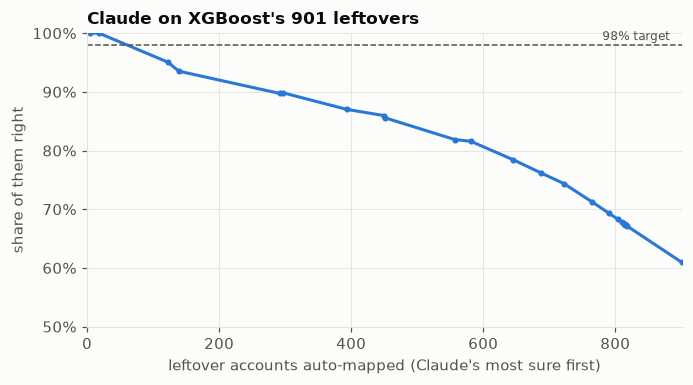

In [5]:
r_rest = np.array([o.chosen_code == gold[i] for o, i in zip(outs, rest)])
picked = np.array([o.chosen_code is not None for o in outs])
stated = np.array([max(o.scores.values()) if o.chosen_code else 0.0 for o in outs])
# Claude's confidence on the leftovers: how right is it at each level?
bands = pd.cut(stated[picked] * 100, [-1, 69, 79, 84, 89, 92, 100], labels=["0–69", "70–79", "80–84", "85–89", "90–92", "93–100"])
table = pd.DataFrame({"band": bands, "right": r_rest[picked]}).groupby("band", observed=False)["right"].agg(["size", "mean"])
table.columns = ["picks", "right"]
display(table.iloc[::-1].style.format({"right": "{:.1%}"}))

# The same leftovers with the LLM method's own calibration and thresholds (fitted on all of dev, notebook 16):
own = ROOT / "artifacts" / "methods" / "llm"
own_cal = Calibrator.from_json(json.loads((own / "calibrator.json").read_text()))
own_t = Thresholds.model_validate_json((own / "thresholds.json").read_text())
# (that calibration belongs to the one-choice question, so it is applied to the one-choice answers on the same leftovers)
from d1.mapper.calibrate import segment_of

p_own = np.array([own_cal.predict(features(list(o.scores.values()))[None, :])[0] if o.chosen_code else 0.0 for o in outs1])
seg_own = np.array([segment_of(dev[i].code, o.chosen_code) for o, i in zip(outs1, rest)])
r_one = np.array([o.chosen_code == gold[i] for o, i in zip(outs1, rest)])
auto_own = np.array([o.chosen_code is not None and own_t.threshold_for(s) is not None and p >= own_t.threshold_for(s) for o, s, p in zip(outs1, seg_own, p_own)])
print(f"with the LLM method's own thresholds, Claude would auto-map {auto_own.sum()} of the {len(rest)} leftovers, "
      f"and {r_one[auto_own].mean():.1%} of those would be right")
gap = np.array([(lambda v: v[0] - v[1])(sorted(o.scores.values(), reverse=True) + [0, 0]) if o.chosen_code else 0.0 for o in outs])
both = picked & (gap >= 0.5)
print(f"the ranked answer's lead over its runner-up: picks leading by 50 points or more: {both.sum()}, right {r_rest[both].mean():.1%}")

curve = precision_curve(stated, r_rest)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(curve["support"], curve["precision"], color=SINGLE, marker="o", markersize=3)
ax.axhline(0.98, color=INK_2, linestyle="--", linewidth=1)
ax.text(len(rest) * 0.98, 0.983, "98% target", ha="right", va="bottom", fontsize=8, color=INK_2)
ax.set(xlabel="leftover accounts auto-mapped (Claude's most sure first)", ylabel="share of them right", title="Claude on XGBoost's 901 leftovers", ylim=(0.5, 1.0), xlim=(0, len(rest)))
ax.yaxis.set_major_formatter(pct())
plt.tight_layout()
plt.show()

- **On the leftovers, Claude is never right 98% of the time with enough accounts behind it:** 94.9% at 90–92 (117 picks); the 5 picks at 93–100 are all right, but 5 is far below the 50 a threshold needs. On all of dev, Claude's 90–94 band was right 98.4% of the time (notebook 16): the easy accounts made its confidence look sharper than it is on hard ones.
- **The curve never reaches the dashed 98% line** with a usable number of accounts. That is why both thresholds are `None`.
- **The ranked answer's second choice doesn't change that.** It gives the calibrator a real runner-up, but even the 549 picks that lead their runner-up by 50 points or more are right only 80.9% of the time.
- **This is why the second stage gets its own calibration.** With the LLM method's own thresholds (fitted on all of dev, for its one-choice question), Claude would have auto-mapped 62 of these leftovers, and only 90.3% of them would have been right. That would quietly break the 98% promise. Fitting on the leftovers caught it.

## 5. When Claude and XGBoost agree

An obvious rule for a second opinion: XGBoost was unsure, but if Claude independently ranks the same group first, trust it?

In [6]:
x_pick = np.array([first[i].chosen_code for i in rest], dtype=object)
c_pick = np.array([o.chosen_code for o in outs], dtype=object)
agree = c_pick == x_pick
x_right = x_pick == gold[rest]
display(pd.DataFrame([
    {"case": "Claude picks the same group as XGBoost", "accounts": int(agree.sum()), "that pick is right": r_rest[agree].mean()},
    {"case": "Claude picks another group (or none)", "accounts": int((~agree).sum()), "Claude right": r_rest[~agree].mean(), "XGBoost right": x_right[~agree].mean()},
]).set_index("case").style.format({c: "{:.1%}" for c in ("that pick is right", "Claude right", "XGBoost right")}, na_rep="–"))
c = precision_curve(stated[agree], r_rest[agree])
best = [(f"{t:.0%}", int(s), f"{p:.1%}") for t, s, p in zip(c["threshold"], c["support"], c["precision"]) if s >= 30][:5]
print("when they agree, by Claude's stated confidence (at least, accounts, right):", best)

,accounts,that pick is right,Claude right,XGBoost right
case,,,,
Claude picks the same group as XGBoost,480,77.7%,–,–
Claude picks another group (or none),421,–,41.8%,5.9%


when they agree, by Claude's stated confidence (at least, accounts, right): [('90%', 99, '96.0%'), ('88%', 114, '95.6%'), ('85%', 227, '91.2%'), ('82%', 229, '91.3%'), ('80%', 292, '88.7%')]


- **They agree on 480 of the 901 leftovers, and then the pick is right 77.7% of the time.** Much better than either alone on these accounts, but far from 98%.
- **Agreement plus Claude's confidence gets closer, not there:** at Claude's 90% or more, 96.0% right (99 accounts). Still short of 98%.
- **When they disagree, Claude is usually the one to follow:** right 41.8% of the time against XGBoost's 5.9%.
- **This is a combination of both opinions,** which is exactly what the ensemble (Task 3.7) learns, with all methods' scores at once. It's not added to the cascade as a hand-made rule.

## 6. What the reviewer reads: Claude's ranked five

Every account that isn't auto-mapped goes to the reviewer with Claude's own ranking: its five most likely groups from the account's shortlist, most likely first, and one sentence explaining the first (`cascade_llm_choices: 5`, `prompts/choose_group_ranked.md`). Nothing is filled in from XGBoost. How often the right group is in the first 1, 3 and 5 places, over the 901 accounts XGBoost leaves, next to the earlier versions:

In [7]:
review = [k for k, i in enumerate(rest) if final[i].decision_path == "review"]
g = gold[rest]
on_list = np.array([g[k] in [c.code for c in lists[i]] for k, i in enumerate(rest)])
x_lists = [[c.code for c in first[i].candidates] for i in rest]
claude5 = [[c.code for c in final[i].review_options()] for i in rest]  # what the reviewer gets now: Claude's ranking only
one_fill = [list(o.scores) + [c for c in x if c not in o.scores] for o, x in zip(outs1, x_lists)]  # the first version


def hits(lists_, k):
    return np.mean([g[n] in l[:k] for n, l in enumerate(lists_)])


rows = [{"the reviewer's list": name, **{f"right group in the first {k}": hits(l, k) for k in (1, 3, 5)}}
        for name, l in (("XGBoost's ranking (no Claude)", x_lists), ("Claude's one pick, then XGBoost's ranking (first version)", one_fill),
                        ("Claude's ranked five, nothing else (the cascade now)", claude5))]
rows.append({"the reviewer's list": "anywhere on the 10-candidate shortlist (the ceiling)", **{f"right group in the first {k}": on_list.mean() for k in (1, 3, 5)}})
display(pd.DataFrame(rows).set_index("the reviewer's list").style.format("{:.1%}"))
print("options Claude gave per account:", pd.Series([len(o.scores) for o in outs]).value_counts().sort_index().to_dict())
print("the reviewer's accounts by Claude's status:", pd.Series([outs[k].status for k in review]).value_counts().to_dict())
u5, u1 = summary["usage"], one.last_usage
print(f"output tokens per call: one choice {u1['output_tokens'] / u1['cached_calls']:,.0f}, ranked five {u5['output_tokens'] / (u5['calls'] + u5['cached_calls']):,.0f}")
print(f"top-1 on the leftovers: one choice {np.mean([o.chosen_code == x for o, x in zip(outs1, g)]):.1%}, ranked five {np.mean([final[i].chosen_code == gold[i] for i in rest]):.1%}")

,right group in the first 1,right group in the first 3,right group in the first 5
the reviewer's list,,,
XGBoost's ranking (no Claude),44.2%,62.9%,67.5%
"Claude's one pick, then XGBoost's ranking (first version)",62.4%,69.0%,70.3%
"Claude's ranked five, nothing else (the cascade now)",60.9%,70.0%,71.0%
anywhere on the 10-candidate shortlist (the ceiling),71.7%,71.7%,71.7%


options Claude gave per account: {0: 1, 1: 1, 2: 5, 3: 16, 4: 127, 5: 751}
the reviewer's accounts by Claude's status: {'ok': 821, 'none': 70, 'invalid': 10}
output tokens per call: one choice 1,721, ranked five 2,466
top-1 on the leftovers: one choice 62.3%, ranked five 60.9%


- **With Claude's ranked five, the right group is among the reviewer's options 71.0% of the time,** against 67.5% with XGBoost's ranking and 70.3% with the first version (Claude's one pick, then XGBoost's next four).
- **The first option is right 60.9% of the time,** against 44.2% with XGBoost's ranking. That is 17 more accounts in every 100 where the reviewer only confirms. Asked for five, Claude places its first choice a little less well than when asked for one (62.3%), which is why the cascade's top-1 is 88.8% here against 89.2% with one pick.
- **Every list hits the same ceiling: 71.7%.** For 28.3% of these accounts the right group is not among the 10 candidates at all, so no ranking of them can show it. Claude's five come within 0.7 points of that ceiling.
- **Most accounts get five options, some four:** 751 of 901 get five. In 110 answers Claude used one of its five places for "none" (it was asked to add that as an extra), and in about 40 a place went to a group from another account's list, which is dropped. The reviewer then sees four, all Claude's.
- **The reviewer's accounts:** for 821 Claude ranked a group first, for 70 it put "none" first (the reviewer still sees its ranking, with "none of these groups" as the reason), and for 10 it put another account's group first.
- **It costs 43% more output per call** (2,466 tokens against 1,721), which is included in the $0.10 per 1,000 accounts of section 3.
- **What would raise the ceiling:** letting Claude name any of the 190 groups for the accounts that go to review. In notebook 16 its "invalid" answers named the right group from outside the account's list 19 times out of 24. That's on the list for the final comparison.

## 7. By source and code scheme

In [8]:
seg = np.array([f"{r.source} · {r.code_scheme}" for r in dev])
out = []
for value in sorted(set(seg)):
    s = seg == value
    out.append({"segment": value, "accounts": int(s.sum()), "auto-mapped": auto["cascade"][s].mean(),
                "top-1 XGBoost": right["xgboost"][s].mean(), "top-1 cascade": right["cascade"][s].mean(),
                "to review": (~auto["cascade"][s]).sum(),
                "review: XGBoost's pick right": right["xgboost"][s & ~auto["cascade"]].mean(), "review: cascade's suggestion right": right["cascade"][s & ~auto["cascade"]].mean()})
display(pd.DataFrame(out).set_index("segment").style.format({c: "{:.1%}" for c in ("auto-mapped", "top-1 XGBoost", "top-1 cascade", "review: XGBoost's pick right", "review: cascade's suggestion right")}))

,accounts,auto-mapped,top-1 XGBoost,top-1 cascade,to review,review: XGBoost's pick right,review: cascade's suggestion right
segment,,,,,,,
llm · legacy,700,14.6%,54.6%,72.1%,598,49.5%,70.1%
llm · llm,800,82.0%,81.5%,82.0%,144,6.9%,9.7%
rules · legacy,1000,85.4%,93.3%,95.7%,146,58.9%,75.3%
rules · pcmn,1000,98.7%,99.1%,99.1%,13,46.2%,46.2%


- **LLM-written accounts with legacy codes gain most:** top-1 from 54.6% to 72.1%. 598 of their 700 accounts go to review, and Claude's first option there is right 70.1% of the time, against XGBoost's 49.5%.
- **Rule-based legacy codes:** top-1 from 93.3% to 95.7%; for the 146 reviewed accounts, Claude's first option is right 75.3% of the time, against 58.9%.
- **LLM-written accounts with LLM codes:** almost unchanged (81.5% → 82.0%). XGBoost auto-maps 82% of them already, and of the 144 that go to review, almost none have the right group on the shortlist (9.7% right). Those are shortlist misses: only a wider choice (the 190 groups) could help there.
- **Rule-based PCMN codes:** nothing to gain, 98.7% are auto-mapped already.

## 8. Random forest first

XGBoost and random forest are tied on dev (74.3% and 74.2% auto-mapped), so the cascade was also fitted with random forest first, the same way, without saving it:

In [9]:
# The same cascade with random forest first: fitted on dev like the saved one, but not saved (save=False).
# Its leftovers are a different set of accounts, so Claude gets new calls the first time this runs; then they are cached.
llm_settings = dict(effort=config.models.mapping.llm_effort)
rf = train_cascade(config, factory, first="random_forest", save=False)
rows = []
for s in (summary, rf):
    rows.append({"first method": s["first"], "first alone: auto": s["first_alone"]["auto_share"], "sent to Claude": s["stages"]["sent_to_llm"],
                 "auto by Claude": s["stages"]["llm_auto"], "cascade: auto": s["auto_share"], "precision of auto": s["auto_precision"],
                 "cascade: top-1": s["top1"], "Claude calls (new + cached)": s["usage"]["calls"] + s["usage"]["cached_calls"]})
display(pd.DataFrame(rows).set_index("first method").style.format({c: "{:.1%}" for c in ("first alone: auto", "cascade: auto", "precision of auto", "cascade: top-1")}))
print("random forest's second-stage thresholds:", rf["second_stage"]["t_auto_by_segment"], "; new Claude calls:", rf["usage"]["calls"])

llm: 20 of 82 calls answered (40 were cached, 0 failed)


llm: 40 of 82 calls answered (40 were cached, 0 failed)


llm: 60 of 82 calls answered (40 were cached, 0 failed)


llm: 80 of 82 calls answered (40 were cached, 0 failed)


llm: 82 of 82 calls answered (40 were cached, 0 failed)


,first alone: auto,sent to Claude,auto by Claude,cascade: auto,precision of auto,cascade: top-1,Claude calls (new + cached)
first method,,,,,,,
xgboost,74.3%,901,0,74.3%,98.5%,88.8%,120
random_forest,74.2%,904,0,74.2%,98.5%,89.0%,122


random forest's second-stage thresholds: {'code_match': None, 'other': None} ; new Claude calls: 82


- **The same picture:** random forest leaves 904 accounts, Claude auto-maps none of them, and the cascade's top-1 is 89.0% against 88.8%, within noise.
- **So the first method doesn't change the conclusion.** Which one the service runs is decided in the final comparison, with intervals, cost and speed.

## 9. What this means, and what is *not* happening

**The answer to this step's question:** on dev, the cascade does **not** auto-map more accounts than XGBoost alone. Claude is clearly better on the accounts XGBoost leaves (60.9% against 44.2% right first), but not sure enough of them to clear 98%. What the cascade does deliver:

- **top-1 of 88.8%**, 4.3 points above XGBoost: a better first suggestion for every account;
- **a review queue where Claude does the ranking:** five options with a one-sentence reason on the first, the right group among them 71.0% of the time (the ceiling is 71.7%);
- **at a third of Claude's cost,** $0.10 per 1,000 accounts, since Claude sees only a quarter of the accounts.

In the final comparison (Task 3.8) the cascade is one candidate. The rule there is the auto share first, then cost, so the cascade wins only if the reviewer's time counts. That is a choice to make there, with these numbers.

**What is not happening:**
- **The 98% bar is not loosened for Claude.** Its leftovers get their own thresholds, and when none reaches 98%, nothing is auto-mapped (section 4 shows what the LLM method's own thresholds would have let through: 90.3% right).
- **No rule is added by hand.** Agreement between both methods (section 5) is left to the ensemble, which learns it from data.
- **No group outside the shortlist reaches the reviewer,** as in notebook 16. The 190-group choice for review accounts is a separate test for the final comparison.
- **The test split is not touched.** Every number here is on dev.

**Next:** the ensemble (Task 3.7), which combines every method's opinion per candidate, then one final comparison of all methods, the cascade and the ensemble.